<a href="https://colab.research.google.com/github/lavanyalagudu16-commits/2520090009_deeplearning/blob/2520090009_skill/skill9(DL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install ultralytics -q


In [2]:

import torch
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from glob import glob

print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable GPU in Runtime settings!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cpu
CUDA Available: False
Enable GPU in Runtime settings!


In [3]:

model = YOLO("yolov8n.pt")

device = 0 if torch.cuda.is_available() else "cpu"

model.to(device)

print("YOLO Model Loaded Successfully!")
print("Model:", "YOLOv8n")
print("Device:", device)


YOLO Model Loaded Successfully!
Model: YOLOv8n
Device: cpu


In [4]:

from ultralytics.utils.downloads import download

download(
    "https://ultralytics.com/assets/coco128.zip",
    dir="/content/datasets",
    unzip=True
)

dataset_path = "/content/datasets/coco128/images/train2017"

image_paths = sorted(glob(dataset_path + "/*.jpg"))

print("Total Images:", len(image_paths))
print("Sample Images:", image_paths[:5])


Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 3.1Kfiles/s 0.1s
Total Images: 128
Sample Images: ['/content/datasets/coco128/images/train2017/000000000009.jpg', '/content/datasets/coco128/images/train2017/000000000025.jpg', '/content/datasets/coco128/images/train2017/000000000030.jpg', '/content/datasets/coco128/images/train2017/000000000034.jpg', '/content/datasets/coco128/images/train2017/000000000036.jpg']


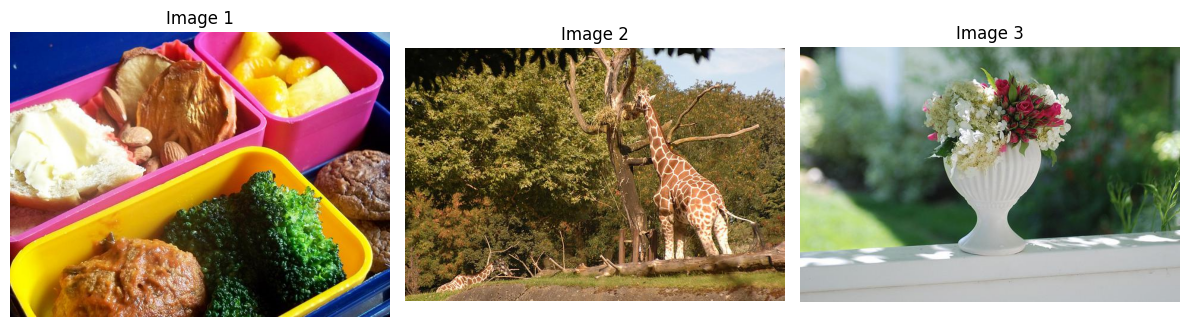

In [5]:

from PIL import Image

plt.figure(figsize=(12, 5))

for i in range(min(3, len(image_paths))):
    plt.subplot(1, 3, i + 1)
    img = Image.open(image_paths[i])
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:

model.model.eval()

# Warm-up runs
for i in range(5):
    model.predict(
        source=image_paths[0],
        imgsz=640,
        device=device,
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

print("Model Evaluation Mode:", not model.model.training)
print("Warm-up Completed Successfully!")


Model Evaluation Mode: True
Warm-up Completed Successfully!


In [7]:

latencies = []

for i in range(30):

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    results = model.predict(
        source=image_paths[i % len(image_paths)],
        imgsz=640,
        device=device,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    latency = (end - start) * 1000
    latencies.append(latency)

avg_latency = np.mean(latencies)

print("Average Latency:", round(avg_latency, 3), "ms")
print("Minimum Latency:", round(min(latencies), 3), "ms")
print("Maximum Latency:", round(max(latencies), 3), "ms")


Average Latency: 186.284 ms
Minimum Latency: 131.041 ms
Maximum Latency: 320.119 ms


In [8]:

batch_size = 8

batch_images = image_paths[:batch_size]

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

batch_results = model.predict(
    source=batch_images,
    imgsz=640,
    device=device,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

end = time.perf_counter()

total_batch_time = end - start

throughput = len(batch_images) / total_batch_time

print("Batch Size:", batch_size)
print("Images Processed:", len(batch_results))
print("Total Batch Time:", round(total_batch_time, 3), "seconds")
print("Throughput:", round(throughput, 3), "images/second")


Batch Size: 8
Images Processed: 8
Total Batch Time: 1.671 seconds
Throughput: 4.786 images/second


In [9]:

if torch.cuda.is_available():

    torch.cuda.reset_peak_memory_stats()

    _ = model.predict(
        source=batch_images,
        imgsz=640,
        device=0,
        verbose=False
    )

    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated() / (1024 ** 2)
    reserved = torch.cuda.memory_reserved() / (1024 ** 2)
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("Allocated GPU Memory:", round(allocated, 2), "MB")
    print("Reserved GPU Memory:", round(reserved, 2), "MB")
    print("Peak GPU Memory:", round(peak_memory, 2), "MB")

else:
    allocated = reserved = peak_memory = 0
    print("GPU memory measurement unavailable.")


GPU memory measurement unavailable.


In [10]:

metrics = model.val(
    data="coco128.yaml",
    imgsz=640,
    batch=8,
    device=device,
    split="val",
    verbose=False
)

map50 = metrics.box.map50
map5095 = metrics.box.map

print("mAP@0.5:", round(map50, 4))
print("mAP@0.5:0.95:", round(map5095, 4))


Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1467.9±493.6 MB/s, size: 45.5 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.9Kit/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.5s/it 23.5s
                   all        128        929      0.629      0.529      0.606      0.447
Speed: 3.3ms preprocess, 170.7ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/runs/detect/val
mAP@0.5: 0.6056
mAP@0.5:0.95: 0.4471


In [11]:

report = {
    "Metric": [
        "mAP@0.5",
        "mAP@0.5:0.95",
        "Average Latency (ms)",
        "Minimum Latency (ms)",
        "Maximum Latency (ms)",
        "Throughput (images/sec)",
        "Allocated GPU Memory (MB)",
        "Peak GPU Memory (MB)"
    ],

    "Value": [
        map50,
        map5095,
        avg_latency,
        min(latencies),
        max(latencies),
        throughput,
        allocated,
        peak_memory
    ]
}

df = pd.DataFrame(report)

print("===== INFERENCE BASELINE REPORT =====")
display(df.round(3))


===== INFERENCE BASELINE REPORT =====


,Metric,Value
0,mAP@0.5,0.606
1,mAP@0.5:0.95,0.447
2,Average Latency (ms),186.284
3,Minimum Latency (ms),131.041
4,Maximum Latency (ms),320.119
5,Throughput (images/sec),4.786
6,Allocated GPU Memory (MB),0.000
7,Peak GPU Memory (MB),0.000


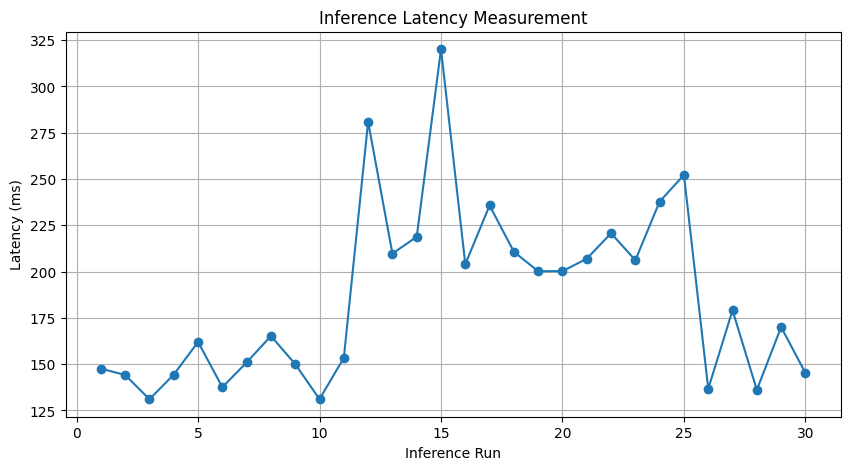

In [12]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(latencies) + 1),
    latencies,
    marker="o"
)

plt.title("Inference Latency Measurement")
plt.xlabel("Inference Run")
plt.ylabel("Latency (ms)")
plt.grid(True)

plt.show()


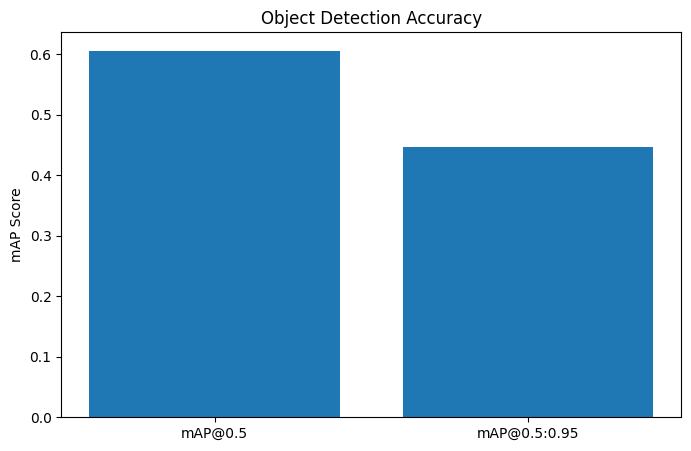

In [13]:

plt.figure(figsize=(8, 5))

plt.bar(
    ["mAP@0.5", "mAP@0.5:0.95"],
    [map50, map5095]
)

plt.title("Object Detection Accuracy")
plt.ylabel("mAP Score")
plt.show()


In [14]:

df.to_csv(
    "Skill_9_Inference_Baseline_Report.csv",
    index=False
)

print("Report saved successfully!")


Report saved successfully!


In [15]:

from google.colab import files

files.download("Skill_9_Inference_Baseline_Report.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>